<a href="https://colab.research.google.com/github/isaacrich080-ctrl/Project1/blob/main/AirBNB_Customer_Reviews_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Airbnb Customer Review Summarization**

In [1]:
# to download Dataset : https://insideairbnb.com/get-the-data/

In [2]:
# Load necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from bs4 import BeautifulSoup
import string
from transformers import BertTokenizer,BertModel,pipeline
from torch import nn
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy
from collections import defaultdict

In [4]:
from google.colab import files

uploaded = files.upload()

Saving Reviews.xlsx to Reviews.xlsx


In [5]:
import pandas as pd

# Load Excel dataset
df = pd.read_excel('Reviews.xlsx')

df.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27934,1094339,2012-04-07,1368195,Michael,We stayed in the apartment for a week and we e...
1,27934,1241042,2012-05-07,2007324,Scott,My girlfriend and I recently stayed in Nuttee'...
2,27934,1523384,2012-06-20,2263352,Marc,I stayed for one month at the condo and was re...
3,27934,1655571,2012-07-08,558987,Leyla,Nuttee was a great host! I really enjoyed her ...
4,27934,1972192,2012-08-13,2359865,Rachel,Nuttee was an amazing host. She and her daught...


In [ ]:
# Basic info
df.head()

,listing_id,id,date,reviewer_id,reviewer_name,comments
0,27934,1094339,2012-04-07,1368195,Michael,We stayed in the apartment for a week and we e...
1,27934,1241042,2012-05-07,2007324,Scott,My girlfriend and I recently stayed in Nuttee'...
2,27934,1523384,2012-06-20,2263352,Marc,I stayed for one month at the condo and was re...
3,27934,1655571,2012-07-08,558987,Leyla,Nuttee was a great host! I really enjoyed her ...
4,27934,1972192,2012-08-13,2359865,Rachel,Nuttee was an amazing host. She and her daught...


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 693647 entries, 0 to 693646
Data columns (total 6 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   listing_id     693647 non-null  int64         
 1   id             693647 non-null  int64         
 2   date           693647 non-null  datetime64[ns]
 3   reviewer_id    693647 non-null  int64         
 4   reviewer_name  693632 non-null  object        
 5   comments       693552 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(2)
memory usage: 31.8+ MB
None


In [7]:
df.shape

(693647, 6)

In [8]:
df=df.iloc[:100,:]

In [9]:
# Data Preprocessing
df['date']=pd.to_datetime(df['date'])
df['comments']=df['comments'].fillna('')

In [10]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [11]:
from bs4 import BeautifulSoup
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = BeautifulSoup(str(text), 'html.parser').get_text()
    text = text.lower()
    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word.isalpha() and word not in stop_words]
    return ' '.join(tokens)

df['clean_comments'] = df['comments'].apply(preprocess_text)

In [12]:
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

In [14]:
import torch
from transformers import AutoTokenizer, AutoModel

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load BERT tokenizer and model
model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(model_name)

# Move model to GPU or CPU
bert_model = bert_model.to(device)
bert_model.eval()

# BERT embedding function
def bert_embedding(text):
    inputs = tokenizer(
        str(text),
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = bert_model(**inputs)

    embedding = outputs.last_hidden_state[:, 0, :]

    return embedding.cpu().numpy().flatten()

# Apply BERT to dataset
df['bert_embedding'] = df['clean_comments'].apply(bert_embedding)

# Check output
print(df[['clean_comments', 'bert_embedding']].head())
print("Embedding shape:", df['bert_embedding'].iloc[0].shape)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


                                      clean_comments  \
0  stayed apartment week enjoyed much nuttee nice...   
1  girlfriend recently stayed nuttee condo month ...   
2  stayed one month condo realy pleased condo flo...   
3  nuttee great host really enjoyed apartment abs...   
4  nuttee amazing host daughter waited us lobby g...   

                                      bert_embedding  
0  [-0.3390964, -0.15549241, 0.8590942, -0.138308...  
1  [-0.12944408, -0.25788847, 0.49584895, -0.1575...  
2  [-0.13837135, -0.12408725, 0.63400036, 0.08875...  
3  [-0.06387808, -0.11280599, 0.46100783, -0.1469...  
4  [-0.18784755, 0.026959414, 0.4700177, 0.052705...  
Embedding shape: (768,)


In [15]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bert_model = bert_model.to(device)
bert_model.eval()

def bert_embedding(text):
    inputs = tokenizer(
        str(text),
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    # Move input tensors to the same device as BERT
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = bert_model(**inputs)

    # Get CLS token embedding
    embedding = outputs.last_hidden_state[:, 0, :]

    return embedding.cpu().numpy().flatten()

In [16]:
# Load the pre-trained sentiment analysis pipeline
bert_sentiment_analyzer = pipeline(
    'sentiment-analysis',
    device=0 if torch.cuda.is_available() else -1
)

# Apply the BERT-based sentiment analysis to clean comments
def analyze_sentiment(text):
    result = bert_sentiment_analyzer(text)[0]
    return result['label'], result['score']

# Apply to the dataset
df[['sentiment_label', 'sentiment_score']] = df['clean_comments'].apply(
    lambda x: pd.Series(analyze_sentiment(x))
)

# Display reviews
df[['comments', 'sentiment_label', 'sentiment_score']].head()

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,comments,sentiment_label,sentiment_score
0,We stayed in the apartment for a week and we e...,POSITIVE,0.999259
1,My girlfriend and I recently stayed in Nuttee'...,POSITIVE,0.996437
2,I stayed for one month at the condo and was re...,POSITIVE,0.993117
3,Nuttee was a great host! I really enjoyed her ...,POSITIVE,0.997826
4,Nuttee was an amazing host. She and her daught...,POSITIVE,0.987587


In [17]:
# Load the pre-trained sentiment analysis pipeline with explicit parameters
bert_sentiment_analyzer = pipeline(
    'sentiment-analysis',
    device=0 if torch.cuda.is_available() else -1
)

# Apply the BERT-based sentiment analysis to clean comments
def analyze_sentiment(text):
    result = bert_sentiment_analyzer(text)[0]
    return result['label'], result['score']

# Apply to the dataset
df[['sentiment_label', 'sentiment_score']] = df['clean_comments'].apply(
    lambda x: pd.Series(analyze_sentiment(x))
)

# Display results
df[['comments', 'sentiment_label', 'sentiment_score']].head()

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,comments,sentiment_label,sentiment_score
0,We stayed in the apartment for a week and we e...,POSITIVE,0.999259
1,My girlfriend and I recently stayed in Nuttee'...,POSITIVE,0.996437
2,I stayed for one month at the condo and was re...,POSITIVE,0.993117
3,Nuttee was a great host! I really enjoyed her ...,POSITIVE,0.997826
4,Nuttee was an amazing host. She and her daught...,POSITIVE,0.987587


In [18]:
# Use TF-IDF to identify key topics
tfidf_vectorizer = TfidfVectorizer(max_features=1000)

tfidf_matrix = tfidf_vectorizer.fit_transform(df['clean_comments'])

feature_names = tfidf_vectorizer.get_feature_names_out()

def get_top_keywords(row):
  # Get the TF-IDF scores for the document
  sorted_indices=doc.toarray()[0].argsort()[::-1]
  top_indices=sorted_indices[:n]
  top_keywords=[feature_names[i] for i in top_indices]
  return top_keywords

In [19]:
# Get top keywords
def get_top_keywords(row, n=5):
    # Get the TF-IDF scores for the document
    sorted_indices = row.toarray()[0].argsort()[::-1]

    top_indices = sorted_indices[:n]

    top_keywords = [feature_names[i] for i in top_indices]

    return top_keywords

# Apply to all documents
df['key_topics'] = [get_top_keywords(doc) for doc in tfidf_matrix]

# Display
df[['comments', 'key_topics']].head()

,comments,key_topics
0,We stayed in the apartment for a week and we e...,"[mins, central, apartment, lot, love]"
1,My girlfriend and I recently stayed in Nuttee'...,"[condo, great, return, recently, meeting]"
2,I stayed for one month at the condo and was re...,"[cheap, music, realy, city, assistant]"
3,Nuttee was a great host! I really enjoyed her ...,"[relaxing, walking, day, walk, great]"
4,Nuttee was an amazing host. She and her daught...,"[huge, little, though, bed, map]"


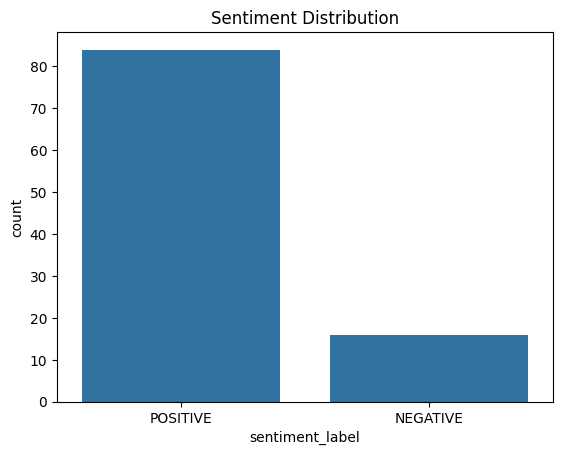

In [20]:
# Plot Sentiment Distribution
sns.countplot(x='sentiment_label',data=df)
plt.title('Sentiment Distribution')
plt.show()

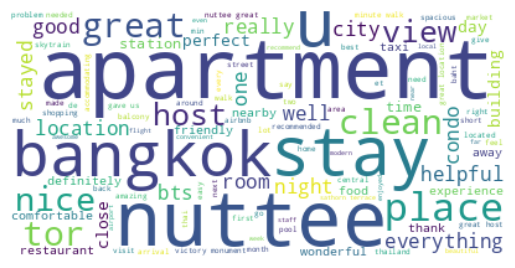

In [21]:
# Word Cloud for most Common word
from wordcloud import WordCloud

text=' '.join(df['clean_comments'])
wordcloud=WordCloud(background_color='white').generate(text)

plt.imshow(wordcloud,interpolation='bilinear')
plt.axis('off')
plt.show()

In [22]:
from transformers import BartTokenizer, BartForConditionalGeneration

tokenizer = BartTokenizer.from_pretrained('facebook/bart-large-cnn')
model = BartForConditionalGeneration.from_pretrained('facebook/bart-large-cnn')

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.58k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/363 [00:00<?, ?B/s]

In [25]:
# Fast summarization without length warnings
def summarize_comments(text):

    inputs = tokenizer(
        str(text),
        return_tensors='pt',
        max_length=512,
        truncation=True
    )

    with torch.no_grad():
        summary_ids = model.generate(
            inputs['input_ids'],
            max_new_tokens=50,
            min_new_tokens=10,
            num_beams=2,
            do_sample=False
        )

    return tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )


# Apply to first 100 comments for testing
df['summary'] = df['clean_comments'].head(100).apply(summarize_comments)

# Display output
df[['clean_comments', 'summary']].head(10)

[transformers] Both `max_new_tokens` (=50) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=10) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=50) and `max_length`(=142) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=10) and `min_length`(=56) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/do

,clean_comments,summary
0,stayed apartment week enjoyed much nuttee nice...,stayed apartment week enjoyed much nuttee nice...
1,girlfriend recently stayed nuttee condo month ...,girlfriend recently stayed nuttee condo month ...
2,stayed one month condo realy pleased condo flo...,stayed one month condo realy pleased condo flo...
3,nuttee great host really enjoyed apartment abs...,nuttee great host really enjoyed apartment abs...
4,nuttee amazing host daughter waited us lobby g...,nuttee amazing host daughter waited us lobby g...
5,nuttee great host waited us arrive late aftern...,nuttee great host waited us arrive late aftern...
6,nuttee wonderfull landlady house clean realy n...,nuttee wonderfull landlady house clean realy n...
7,wonderful time bangkok thanks small part choic...,wonderful time bangkok thanks small part choic...
8,clean spacious comfortable safe great location...,Clean spacious comfortable safe great location...
9,would like thankk occasion know nuttee stay co...,would like thankk occasion know nuttee stay co...


In [26]:
df[['comments', 'clean_comments', 'sentiment_label',
    'sentiment_score', 'summary', 'key_topics']].head()

,comments,clean_comments,sentiment_label,sentiment_score,summary,key_topics
0,We stayed in the apartment for a week and we e...,stayed apartment week enjoyed much nuttee nice...,POSITIVE,0.999259,stayed apartment week enjoyed much nuttee nice...,"[mins, central, apartment, lot, love]"
1,My girlfriend and I recently stayed in Nuttee'...,girlfriend recently stayed nuttee condo month ...,POSITIVE,0.996437,girlfriend recently stayed nuttee condo month ...,"[condo, great, return, recently, meeting]"
2,I stayed for one month at the condo and was re...,stayed one month condo realy pleased condo flo...,POSITIVE,0.993117,stayed one month condo realy pleased condo flo...,"[cheap, music, realy, city, assistant]"
3,Nuttee was a great host! I really enjoyed her ...,nuttee great host really enjoyed apartment abs...,POSITIVE,0.997826,nuttee great host really enjoyed apartment abs...,"[relaxing, walking, day, walk, great]"
4,Nuttee was an amazing host. She and her daught...,nuttee amazing host daughter waited us lobby g...,POSITIVE,0.987587,nuttee amazing host daughter waited us lobby g...,"[huge, little, though, bed, map]"


In [27]:
print(df.columns.tolist())

['listing_id', 'id', 'date', 'reviewer_id', 'reviewer_name', 'comments', 'clean_comments', 'bert_embedding', 'sentiment_label', 'sentiment_score', 'key_topics', 'summary']


In [28]:
print("Review:",df['comments'][4])
print()
print("Cleaned Review:",df['clean_comments'][4])
print()
print("Sentiment Label:",df['sentiment_label'][4])
print()
print("Sentiment Score:",df['sentiment_score'][4])
print()
print("Summary:",df['summary'][4])
print()
print("Key Topics:",df['key_topics'][4])

Review: Nuttee was an amazing host. She and her daughter waited for us at the lobby and gave us a quick rundown of the place. It's a studio apartment, with a classy partition dividing the bedroom from the living room -- and the view from the balcony is awesome. Bed was huge, but if you're coming in a group of 3, the sofa may not always be the most comfortable place for the last guy (bed IS huge enough for three to sleep in though). Shower pressure in the main bathroom was a little low, but we could deal with it. Make sure to ask Nuttee or her assistant to write down the condominium's address for you in Thai, though it will be best if you print out a map yourself -- most of our taxi/tuk-tuk/motorcycle drivers needed a little pointer about where exactly it was. That said, it was a very central location, just slightly away from the sometimes overwhelming hustle and bustle of Pratunam. Warmly recommended. 

Cleaned Review: nuttee amazing host daughter waited us lobby gave us quick rundown 